# 04 - Árvores de decisão

Foram treinadas árvores para regressão e classificação, considerando critérios de divisão distintos e controles de complexidade. O ajuste de hiperparâmetros foi realizado com GridSearchCV e validação cruzada no conjunto de treinamento. São avaliadas árvores sem restrição de profundidade e árvores ajustadas, com análise de desempenho, estrutura e regras extraídas.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
if not (ROOT/'data').exists(): ROOT = ROOT.parent
assert (ROOT/'src').exists(), 'Abra o notebook a partir da pasta do projeto.'
sys.path.insert(0,str(ROOT))
TAB=ROOT/'reports'/'tables'; FIG=ROOT/'reports'/'figures'
META=json.loads((ROOT/'data/processed/metadata.json').read_text(encoding='utf-8'))
print('Projeto:', ROOT)

Projeto: C:\Users\Felipe Erik\Desktop\Trabalho2IA\final\student_career_ia


## Treinamento e validação
Nesta etapa são ajustados os modelos com o conjunto de treinamento e validação cruzada K-fold. O conjunto de teste é reservado à avaliação final. Os parâmetros e as métricas da execução são salvos na pasta de tabelas.

In [2]:
from src.training import train_group

# Execução independente do treinamento para regressão e classificação.
# Busca de parâmetros e validação cruzada são feitas somente sobre o treino.
for tarefa in ('regression', 'classification'):
    resultados = train_group(tarefa, ['Arvore_sem_limite', 'Arvore_ajustada'])
    display(resultados.round(4))

regression: Arvore_sem_limite | ajuste 1.27 s
regression: Arvore_ajustada | ajuste 95.07 s


,task,model,split,MAE,MSE,RMSE,MAPE,R2,MedAE
0,regression,Arvore_sem_limite,train,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
1,regression,Arvore_sem_limite,test,3.7481,24.1089,4.9101,1.8354,0.9666,2.9500
2,regression,Arvore_ajustada,train,2.8739,13.4872,3.6725,1.3938,0.9812,2.3643
3,regression,Arvore_ajustada,test,3.7098,22.4710,4.7404,1.8073,0.9689,3.0794


classification: Arvore_sem_limite | ajuste 1.32 s
classification: Arvore_ajustada | ajuste 28.08 s


,task,model,split,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,classification,Arvore_sem_limite,train,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,classification,Arvore_sem_limite,test,0.7329,0.8335,0.8221,0.8278,0.6186,0.8241
2,classification,Arvore_ajustada,train,0.8230,0.8427,0.9508,0.8935,0.8199,0.9228
3,classification,Arvore_ajustada,test,0.8180,0.8417,0.9445,0.8902,0.8055,0.9157


In [3]:
import pickle

def load_model(task, name):
    # Deserializar SOMENTE os modelos do próprio projeto / fonte confiável.
    path=ROOT/'models'/f'{task}_{name}.pkl'
    with path.open('rb') as f: return pickle.load(f)

## Critérios e hiperparâmetros testados
Classificação: Gini e entropia. Regressão: erro quadrático (squared_error) e erro absoluto (absolute_error). Busca com validação cruzada de 5 folds e grades para max_depth e min_samples_leaf.

In [4]:
from src.models import model_specs
for task in ['regression','classification']:
    specs=model_specs(task=='classification','standard')
    print(task, 'grade:',specs['Arvore_ajustada'][1])
params=json.loads((TAB/'best_parameters.json').read_text(encoding='utf-8'))
for task in ['regression','classification']: print(task,'melhores parâmetros:',params.get(f'{task}:Arvore_ajustada'))

regression grade: {'model__max_depth': [6, 12], 'model__min_samples_leaf': [10, 20], 'model__criterion': ['squared_error', 'absolute_error']}
classification grade: {'model__max_depth': [6, 12], 'model__min_samples_leaf': [10, 20], 'model__criterion': ['gini', 'entropy']}
regression melhores parâmetros: {'model__criterion': 'squared_error', 'model__max_depth': 12, 'model__min_samples_leaf': 10}
classification melhores parâmetros: {'model__criterion': 'entropy', 'model__max_depth': 6, 'model__min_samples_leaf': 10}


## Métricas e tamanho das árvores

In [5]:
m=pd.read_csv(TAB/'model_metrics.csv');e=pd.read_csv(TAB/'efficiency.csv')
for task in ['regression','classification']:
    print('\n',task)
    display(m[(m.task==task)&m.model.str.startswith('Arvore')].round(4))
    display(e[(e.task==task)&e.model.str.startswith('Arvore')][['model','train_seconds','model_bytes','complexity']])


 regression


,task,model,split,MAE,MSE,RMSE,MAPE,R2,MedAE,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
2,regression,Arvore_sem_limite,train,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN
3,regression,Arvore_sem_limite,test,3.7481,24.1089,4.9101,1.8354,0.9666,2.9500,NaN,NaN,NaN,NaN,NaN,NaN
4,regression,Arvore_ajustada,train,2.8739,13.4872,3.6725,1.3938,0.9812,2.3643,NaN,NaN,NaN,NaN,NaN,NaN
5,regression,Arvore_ajustada,test,3.7098,22.4710,4.7404,1.8073,0.9689,3.0794,NaN,NaN,NaN,NaN,NaN,NaN


,model,train_seconds,model_bytes,complexity
1,Arvore_sem_limite,1.126493,5681345,"{""depth"": 28, ""nodes"": 78853, ""leaves"": 39427}"
2,Arvore_ajustada,76.465205,295875,"{""depth"": 12, ""nodes"": 4055, ""leaves"": 2028}"



 classification


,task,model,split,MAE,MSE,RMSE,MAPE,R2,MedAE,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
12,classification,Arvore_sem_limite,train,NaN,NaN,NaN,NaN,NaN,NaN,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
13,classification,Arvore_sem_limite,test,NaN,NaN,NaN,NaN,NaN,NaN,0.7329,0.8335,0.8221,0.8278,0.6186,0.8241
14,classification,Arvore_ajustada,train,NaN,NaN,NaN,NaN,NaN,NaN,0.8230,0.8427,0.9508,0.8935,0.8199,0.9228
15,classification,Arvore_ajustada,test,NaN,NaN,NaN,NaN,NaN,NaN,0.8180,0.8417,0.9445,0.8902,0.8055,0.9157


,model,train_seconds,model_bytes,complexity
6,Arvore_sem_limite,1.148059,950537,"{""depth"": 46, ""nodes"": 11831, ""leaves"": 5916}"
7,Arvore_ajustada,24.009003,11960,"{""depth"": 6, ""nodes"": 99, ""leaves"": 50}"


## Visualização e extração de 3 regras da árvore final
As regras são extraídas diretamente dos limiares aprendidos no treino.


 regression profundidade: 12 nós: 4055 folhas: 2028
|--- num__Resume_Score <= 98.50
|   |--- num__Resume_Score <= 84.50
|   |   |--- num__Interview_Score <= 54.50
|   |   |   |--- truncated branch of depth 10
|   |   |--- num__Interview_Score >  54.50
|   |   |   |--- truncated branch of depth 10
|   |--- num__Resume_Score >  84.50
|   |   |--- num__Interview_Score <= 71.50
|   |   |   |--- truncated branch of depth 10
|   |   |--- num__Interview_Score >  71.50
|   |   |   |--- truncated branch of depth 10
|--- num__Resume_Score >  98.50
|   |--- num__Programming_Skill <= 7.50
|   |   |--- num__Interview_Score <= 76.50
|   |   |   |--- truncated branch of depth 10
|   |   |--- num__Interview_Score >  76.50
|   |   |   |--- truncated branch of depth 10
|   |--- num__Programming_Skill >  7.50
|   |   |--- num__Internships <= 4.50
|   |   |   |--- truncated branch of depth 10
|   |   |--- num__Internships >  4.50
|   |   |   |--- truncated branch of depth 10



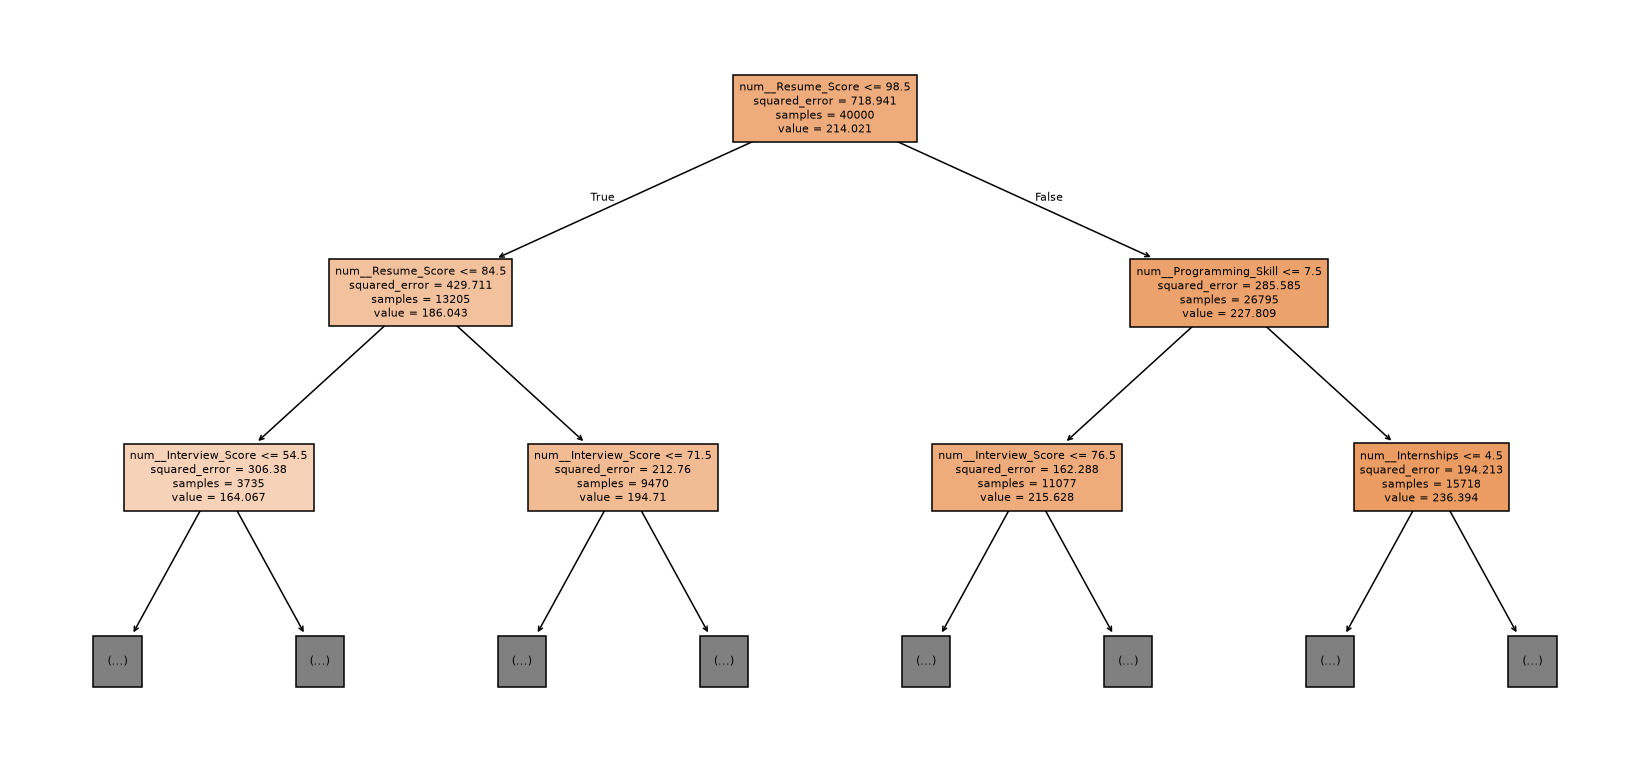


 classification profundidade: 6 nós: 99 folhas: 50
|--- num__Employability_Score <= 199.97
|   |--- num__Employability_Score <= 179.92
|   |   |--- num__Employability_Score <= 160.03
|   |   |   |--- truncated branch of depth 4
|   |   |--- num__Employability_Score >  160.03
|   |   |   |--- truncated branch of depth 4
|   |--- num__Employability_Score >  179.92
|   |   |--- num__Age <= 27.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- num__Age >  27.50
|   |   |   |--- truncated branch of depth 4
|--- num__Employability_Score >  199.97
|   |--- num__Employability_Score <= 219.97
|   |   |--- num__Hackathons <= 5.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- num__Hackathons >  5.50
|   |   |   |--- truncated branch of depth 4
|   |--- num__Employability_Score >  219.97
|   |   |--- num__Employability_Score <= 262.62
|   |   |   |--- truncated branch of depth 4
|   |   |--- num__Employability_Score >  262.62
|   |   |   |--- truncated branch of depth 4



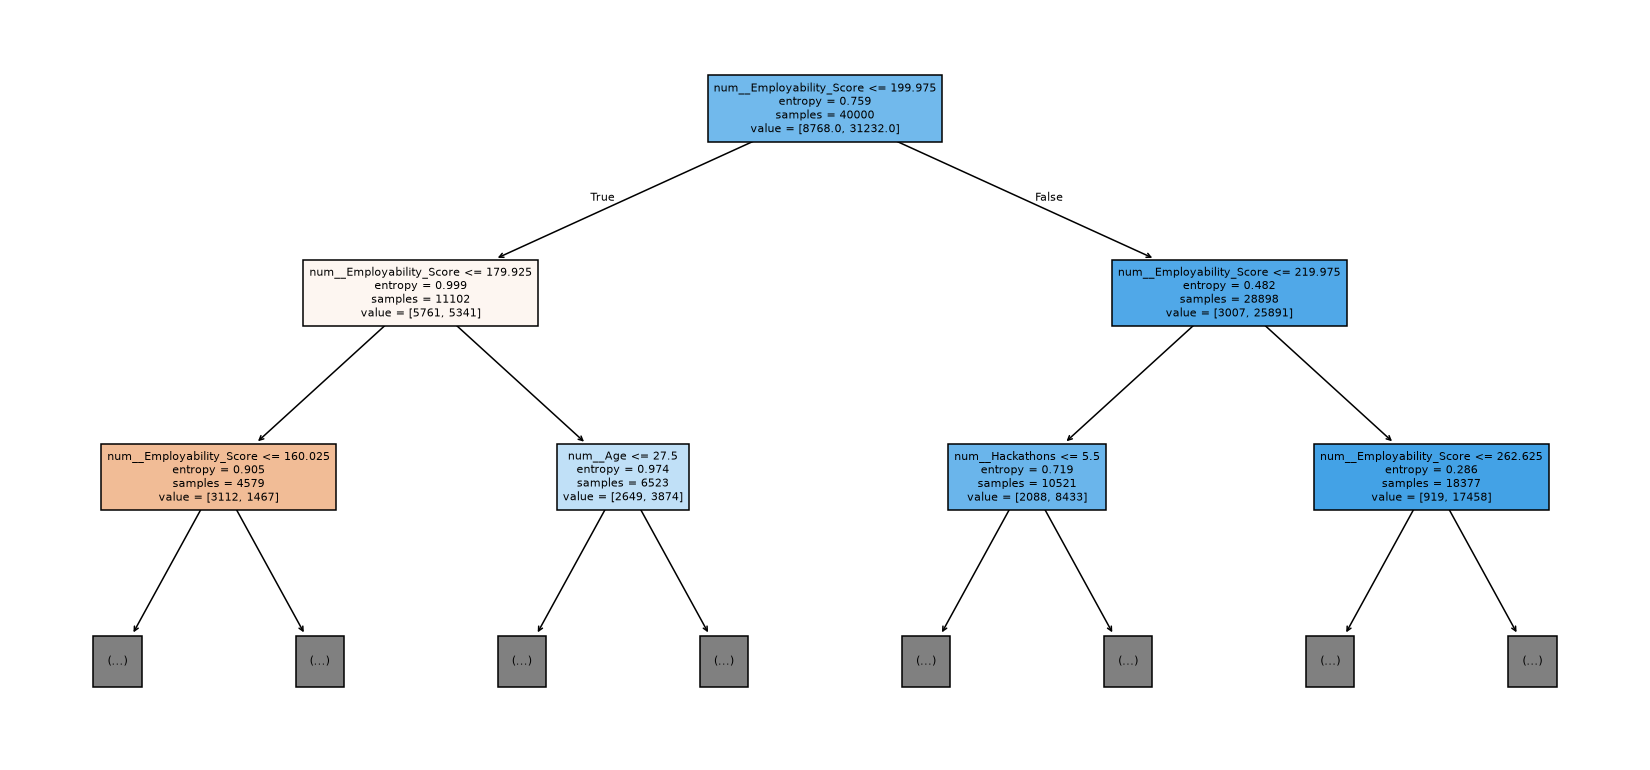

In [6]:
from sklearn.tree import _tree, export_text
for task in ['regression','classification']:
    model=load_model(task,'Arvore_ajustada'); core=model.named_steps['model']; names=list(model.named_steps['prep'].get_feature_names_out())
    print('\n',task,'profundidade:',core.get_depth(),'nós:',core.tree_.node_count,'folhas:',core.get_n_leaves())
    print(export_text(core,feature_names=names,max_depth=2)[:2200])
    display(Image(filename=str(FIG/f'{task}_tree.png')))

## Comparação interpretativa
A comparação entre os primeiros caminhos SE–ENTÃO extraídos da árvore e a base do especialista mostra que árvores aprendem limiares dos dados e podem combinar várias variáveis, regras especialistas dependem de elaboração explícita. A árvore sem limite pode memorizar padrões de treino.